# GhostTape randomness proof

GhostTape's price moves come from an ESP32's hardware random number generator (`esp_random()`).
This notebook puts 10 MB from that chip next to well-known software generators and one famously bad one,
and runs the same statistical tests on all of them.

**What this notebook can and cannot show.** Statistical tests can only say *"no detectable pattern"*.
Good software generators (which are fully predictable if you know the seed) pass them too, and so does the same
ESP32 with its radio switched off, which Espressif says is only pseudo-random. The claim that GhostTape's numbers
are *truly* random rests on the physical source: Espressif documents that the ESP32 RNG is true random while the
RF subsystem (Wi-Fi/Bluetooth) is on and not asleep, and the GhostTape firmware proves that condition (Wi-Fi STA on,
sleep off, one completed Wi-Fi scan) before it sends a single number. The tests are here to show nothing is
*broken*, and to show they are sharp enough to catch a bad generator (RANDU).

| Source | What it is | Expected |
|---|---|---|
| ESP32 radio ON | `esp_random()`, Wi-Fi on + sleep off, radio verified by the firmware | true random (Espressif's condition met) |
| ESP32 radio OFF | same chip, `WiFi.mode(WIFI_OFF)` (control build `RADIO_OFF_CONTROL=1`) | pseudo-random per Espressif; the honesty control |
| MT19937 | Python `random.getrandbits`, fixed seed | good PRNG, fully predictable from the seed |
| PCG64 | NumPy `default_rng`, fixed seed | good PRNG, fully predictable from the seed |
| os.urandom | the operating system's CSPRNG | cryptographically secure PRNG |
| RANDU | IBM's 1960s LCG, x(n+1) = 65539 * x(n) mod 2^31 (top byte of each output) | known-bad control: the tests must catch it |

**How to run.** Locally: put the captures in `data/` at the repo root (made with `tools/capture.py`) and run all cells.
In Google Colab: run all cells; the first cell asks you to upload `esp32_radio_on.bin` and `esp32_radio_off.bin`
(and optionally `esp32_radio_on_2.bin`). You can also mount Google Drive and set `GHOSTTAPE_DATA_DIR`.

In [1]:
import os, sys, math, random, json, subprocess, time
from pathlib import Path
import numpy as np
from scipy import special, stats
import matplotlib
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules
N = 10 * 1024 * 1024          # bytes per source (10 MB, the size of each ESP32 capture)
SEED = 20261005               # fixed seed for the software PRNGs (same seed = same bytes, every run)
NIST_BITS = 1_000_000         # NIST SP 800-22 sequence length (1 Mbit)
NIST_SEQS = 10                # number of disjoint 1-Mbit sequences for the NIST pass-proportion check
ALPHA = 0.01                  # pass threshold: p >= 0.01

plt.rcParams.update({'figure.dpi': 72, 'savefig.dpi': 110, 'font.size': 9})

if IN_COLAB:
    DATA_DIR = Path(os.environ.get('GHOSTTAPE_DATA_DIR', '/content/data'))
    OUT_DIR = Path('/content/randomness_out')
else:
    DATA_DIR = Path(os.environ.get('GHOSTTAPE_DATA_DIR', '../data' if Path('../data').exists() else 'data'))
    OUT_DIR = Path('../docs/randomness') if Path('../docs').exists() else Path('randomness_out')
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED = ['esp32_radio_on.bin', 'esp32_radio_off.bin']
OPTIONAL = ['esp32_radio_on_2.bin']
missing = [f for f in REQUIRED if not (DATA_DIR / f).exists()]
if missing and IN_COLAB:
    from google.colab import files
    print('Upload', ', '.join(REQUIRED), '(and optionally', OPTIONAL[0] + ')')
    for name, content in files.upload().items():
        (DATA_DIR / Path(name).name).write_bytes(content)
    missing = [f for f in REQUIRED if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f'Missing {missing} in {DATA_DIR.resolve()}. Capture them with tools/capture.py '
                            'or set GHOSTTAPE_DATA_DIR.')
print('Python', sys.version.split()[0], '| numpy', np.__version__, '| Colab' if IN_COLAB else '| local')
print('DATA_DIR =', DATA_DIR.resolve()); print('OUT_DIR  =', OUT_DIR.resolve())
for f in REQUIRED + OPTIONAL:
    p = DATA_DIR / f
    print(f'  {f:24s}', f'{p.stat().st_size:,} bytes' if p.exists() else '(not present)')

Python 3.14.3 | numpy 2.5.3 | local
DATA_DIR = C:\Users\prave\OneDrive\Documents\GhostTapeTradingTRNG\data
OUT_DIR  = C:\Users\prave\OneDrive\Documents\GhostTapeTradingTRNG\docs\randomness
  esp32_radio_on.bin       10,485,760 bytes
  esp32_radio_off.bin      10,485,760 bytes
  esp32_radio_on_2.bin     1,048,576 bytes


## 1. Build the six byte streams (10 MB each)

The ESP32 files are the raw `uint32` words from `esp_random()` exactly as the firmware wrote them
(`CAPTURE_MODE=1`, 921,600 baud). `tools/capture.py` drops the first second of the stream so no boot text gets in;
the next cell checks for it anyway.

In [2]:
def load_capture(name):
    d = np.fromfile(DATA_DIR / name, dtype=np.uint8)
    if len(d) < N:
        raise ValueError(f'{name} has {len(d):,} bytes, need {N:,}')
    raw = d[:N].tobytes()
    for marker in (b'ets ', b'rst:', b'boot:', b'GT1,'):   # boot / status text would mean a dirty capture
        hits = raw.count(marker)
        # by chance a 4-byte string appears ~0.6x in 10 MB, a 5-byte one almost never
        print(f'  {name}: "{marker.decode()}" appears {hits}x')
    return d[:N]

def randu_words(n, seed=1):
    # x(n+1) = 65539 * x(n) mod 2^31, vectorised with a jump-ahead multiplier (a^K mod 2^31)
    a, m, K = 65539, 1 << 31, 4096
    first = np.empty(K, np.uint64); x = seed
    for i in range(K):
        x = (a * x) % m; first[i] = x
    aK = np.uint64(pow(a, K, m)); out = np.empty(-(-n // K) * K, np.uint64); out[:K] = first; cur = first
    for b in range(1, len(out) // K):
        cur = (cur * aK) % np.uint64(m); out[b * K:(b + 1) * K] = cur
    return out[:n]

randu = randu_words(N)
assert all((9 * int(randu[i]) - 6 * int(randu[i + 1]) + int(randu[i + 2])) % (1 << 31) == 0 for i in range(1000))

SOURCES = {
    'ESP32 radio ON':  load_capture('esp32_radio_on.bin'),
    'ESP32 radio OFF': load_capture('esp32_radio_off.bin'),
    'MT19937':         np.frombuffer(random.Random(SEED).getrandbits(8 * N).to_bytes(N, 'little'), np.uint8),
    'PCG64':           np.frombuffer(np.random.default_rng(SEED).bytes(N), np.uint8),
    'os.urandom':      np.frombuffer(os.urandom(N), np.uint8),
    'RANDU':           (randu >> np.uint64(23)).astype(np.uint8),   # top 8 of 31 bits: RANDU's best bits
}
NAMES = list(SOURCES)
for k, v in SOURCES.items():
    print(f'{k:16s} {len(v):,} bytes  first 8: {v[:8].tobytes().hex()}')

  esp32_radio_on.bin: "ets " appears 0x
  esp32_radio_on.bin: "rst:" appears 0x
  esp32_radio_on.bin: "boot:" appears 0x
  esp32_radio_on.bin: "GT1," appears 0x
  esp32_radio_off.bin: "ets " appears 0x
  esp32_radio_off.bin: "rst:" appears 0x
  esp32_radio_off.bin: "boot:" appears 0x
  esp32_radio_off.bin: "GT1," appears 0x


ESP32 radio ON   10,485,760 bytes  first 8: f9c88fa3a940da35
ESP32 radio OFF  10,485,760 bytes  first 8: 3611460b8b8a24c7
MT19937          10,485,760 bytes  first 8: 0024de4642ccb18b
PCG64            10,485,760 bytes  first 8: 2af6cf480441da56
os.urandom       10,485,760 bytes  first 8: 732a37020bc32843
RANDU            10,485,760 bytes  first 8: 00000000030b2788


## 2. The tests, in one sentence each

| Test | Plain-English meaning | Pass rule |
|---|---|---|
| Byte chi-square | Does every byte value 0-255 turn up about equally often? | p >= 0.01 |
| Shannon entropy | How many bits of surprise per byte (8.0 is the maximum)? | >= 7.9995 bits/byte (10 MB) |
| Serial correlation | Does one byte tell you anything about the next (linear correlation)? | p >= 0.01 |
| Monte-Carlo pi | Throw random points at a square; does the share inside the circle give pi? | p >= 0.01 |
| NIST frequency (monobit) | Are there as many 1-bits as 0-bits? | p >= 0.01 and >= 9/10 sequences pass |
| NIST block frequency | Is the 1/0 balance also right inside each 20,000-bit block? | p >= 0.01 and >= 9/10 |
| NIST runs | Do streaks of identical bits (runs) have the right lengths, neither too choppy nor too sticky? | p >= 0.01 and >= 9/10 |
| NIST approximate entropy | Do all 10-bit and 11-bit patterns turn up as often as pure chance predicts? | p >= 0.01 and >= 9/10 |
| Autocorrelation, lags 1-32 | Is a byte correlated with the byte 1, 2, ... 32 places later? | Bonferroni p >= 0.01 |
| 3D triples chi-square | Are three bytes in a row spread evenly through a 16x16x16 cube? (This is the test RANDU is famous for failing.) | p >= 0.01 |

NIST tests follow SP 800-22 rev 1a; each runs on the first 1 Mbit (MSB first) and, for the pass-proportion check,
on 10 disjoint 1-Mbit sequences (NIST's acceptable proportion for 10 sequences at alpha = 0.01 is 9/10).
At p >= 0.01 a perfect generator still fails about 1 test in 100 by pure chance, and `os.urandom` gives new bytes
on every run, so its numbers change each time the notebook runs.

In [3]:
def chi2_bytes(d):
    c = np.bincount(d, minlength=256); e = len(d) / 256
    x = float(((c - e) ** 2 / e).sum()); return x, float(stats.chi2.sf(x, 255))

def shannon_entropy(d):
    p = np.bincount(d, minlength=256) / len(d); p = p[p > 0]; return float(-(p * np.log2(p)).sum())

def serial_correlation(d):           # ent-style lag-1 correlation (circular)
    x = d.astype(np.float64); r = float(np.corrcoef(x, np.roll(x, -1))[0, 1])
    return r, float(2 * stats.norm.sf(abs(r) * math.sqrt(len(d))))

def monte_carlo_pi(d):               # ent-style: 6 bytes -> one (x, y) point of two 24-bit coordinates
    n = len(d) // 6; v = d[:n * 6].reshape(n, 6).astype(np.float64)
    X = (v[:, 0] * 65536 + v[:, 1] * 256 + v[:, 2]) / (2.0 ** 24 - 1)
    Y = (v[:, 3] * 65536 + v[:, 4] * 256 + v[:, 5]) / (2.0 ** 24 - 1)
    inside = int((X * X + Y * Y <= 1).sum()); p0 = math.pi / 4
    z = (inside - n * p0) / math.sqrt(n * p0 * (1 - p0))
    return 4 * inside / n, float(2 * stats.norm.sf(abs(z)))

def to_bits(d, start_bit=0, nbits=NIST_BITS):
    b0 = start_bit // 8; return np.unpackbits(d[b0:b0 + (nbits + 7) // 8])[:nbits]

def nist_frequency(b):
    s = int(np.sum(2 * b.astype(np.int64) - 1))
    return float(special.erfc(abs(s) / math.sqrt(len(b)) / math.sqrt(2)))

def nist_block_frequency(b, M=20000):   # SP 800-22: M >= 20, M > 0.01 n, N < 100
    nb = len(b) // M; pi = b[:nb * M].reshape(nb, M).mean(1)
    return float(special.gammaincc(nb / 2, 4 * M * ((pi - 0.5) ** 2).sum() / 2))

def nist_runs(b):
    n = len(b); pi = b.mean()
    if abs(pi - 0.5) >= 2 / math.sqrt(n):      # frequency pre-test failed -> runs test not applicable
        return 0.0
    v = 1 + np.count_nonzero(b[1:] != b[:-1])
    return float(special.erfc(abs(v - 2 * n * pi * (1 - pi)) / (2 * math.sqrt(2 * n) * pi * (1 - pi))))

def nist_approximate_entropy(b, m=10):          # SP 800-22: m < floor(log2 n) - 5 = 14 for n = 1e6
    n = len(b)
    def phi(mm):
        ext = np.concatenate([b, b[:mm - 1]]).astype(np.int64); codes = np.zeros(n, np.int64)
        for k in range(mm):
            codes = (codes << 1) | ext[k:k + n]
        c = np.bincount(codes, minlength=1 << mm) / n; c = c[c > 0]
        return float((c * np.log(c)).sum())
    apen = phi(m) - phi(m + 1)
    return float(special.gammaincc(2 ** (m - 1), n * (math.log(2) - apen)))

def autocorrelation(d, maxlag=32):
    x = d.astype(np.float64) - d.mean(); v = float((x * x).mean())
    r = np.array([(x[:-k] * x[k:]).mean() / v for k in range(1, maxlag + 1)])
    zmax = float(np.abs(r).max() * math.sqrt(len(d)))
    return r, min(1.0, maxlag * 2 * float(stats.norm.sf(zmax)))   # Bonferroni over the 32 lags

def triples_chi2(d, bits_per_axis=4):
    n = len(d) // 3; t = (d[:n * 3].reshape(n, 3) >> (8 - bits_per_axis)).astype(np.int64)
    idx = (t[:, 0] << (2 * bits_per_axis)) | (t[:, 1] << bits_per_axis) | t[:, 2]
    k = 1 << (3 * bits_per_axis); c = np.bincount(idx, minlength=k); e = n / k
    x = float(((c - e) ** 2 / e).sum()); return x, float(stats.chi2.sf(x, k - 1))

NIST = {'NIST frequency': nist_frequency, 'NIST block frequency': nist_block_frequency,
        'NIST runs': nist_runs, 'NIST approximate entropy': nist_approximate_entropy}

In [4]:
results = {}       # results[source][test] = dict(value=..., p=..., ok=bool, show=str)
acf = {}
t0 = time.time()
for name, d in SOURCES.items():
    R = {}
    x, p = chi2_bytes(d);            R['Byte chi-square'] = dict(value=x, p=p, ok=p >= ALPHA, show=f'chi2={x:.0f} p={p:.3f}')
    h = shannon_entropy(d);          R['Shannon entropy'] = dict(value=h, p=None, ok=h >= 7.9995, show=f'{h:.6f} bit')
    r, p = serial_correlation(d);    R['Serial correlation'] = dict(value=r, p=p, ok=p >= ALPHA, show=f'r={r:+.5f} p={p:.3f}')
    pi_est, p = monte_carlo_pi(d);   R['Monte-Carlo pi'] = dict(value=pi_est, p=p, ok=p >= ALPHA, show=f'{pi_est:.5f} p={p:.3f}')
    for tname, fn in NIST.items():
        ps = [fn(to_bits(d, i * NIST_BITS)) for i in range(NIST_SEQS)]
        passed = sum(q >= ALPHA for q in ps)
        R[tname] = dict(value=ps, p=ps[0], ok=ps[0] >= ALPHA and passed >= 9, show=f'p={ps[0]:.3f} {passed}/{NIST_SEQS}')
    r, p = autocorrelation(d); acf[name] = r
    R['Autocorrelation 1-32'] = dict(value=float(np.abs(r).max()), p=p, ok=p >= ALPHA, show=f'max abs r={np.abs(r).max():.5f} p={p:.3f}')
    x, p = triples_chi2(d);          R['3D triples chi-square'] = dict(value=x, p=p, ok=p >= ALPHA, show=f'chi2={x:.0f} p={p:.3f}' if p > 0 else f'chi2={x:.0f} p<1e-300')
    results[name] = R
    print(f'{name:16s} done ({time.time() - t0:.0f} s)')
TESTS = list(results[NAMES[0]])

ESP32 radio ON   done (6 s)


ESP32 radio OFF  done (13 s)


MT19937          done (19 s)


PCG64            done (25 s)


os.urandom       done (31 s)


RANDU            done (37 s)


## 3. Results table

`PASS` / `FAIL` per test per source with the key number. NIST cells show the p-value of the first 1-Mbit sequence and
how many of the 10 sequences passed.

+--------------------------+-------------------------------+-------------------------------+-------------------------------+-------------------------------+-------------------------------+-------------------------------+
|Test                      |         ESP32 radio ON        |        ESP32 radio OFF        |            MT19937            |             PCG64             |           os.urandom          |             RANDU             |
+--------------------------+-------------------------------+-------------------------------+-------------------------------+-------------------------------+-------------------------------+-------------------------------+
|Byte chi-square           | PASS chi2=269 p=0.258         | PASS chi2=285 p=0.093         | PASS chi2=241 p=0.727         | PASS chi2=275 p=0.181         | PASS chi2=295 p=0.044         | PASS chi2=286 p=0.086         |
|Shannon entropy           | PASS 7.999981 bit             | PASS 7.999980 bit             | PASS 7.999983 bit      

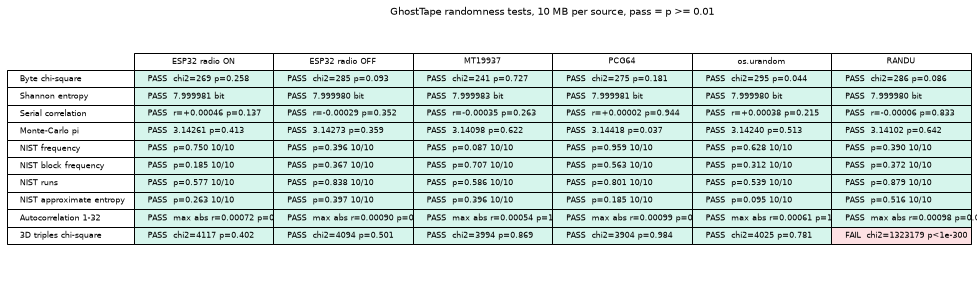

In [5]:
w0, w = 26, 31
line = '+' + '-' * w0 + ('+' + '-' * w) * len(NAMES) + '+'
print(line); print('|' + 'Test'.ljust(w0) + ''.join('|' + n.center(w) for n in NAMES) + '|'); print(line)
for t in TESTS:
    print('|' + t.ljust(w0) + ''.join('|' + ('PASS ' if results[n][t]['ok'] else 'FAIL ').rjust(6) + results[n][t]['show'][:w - 6].ljust(w - 6) for n in NAMES) + '|')
print(line)
print('|' + 'Tests passed'.ljust(w0) + ''.join('|' + f"{sum(results[n][t]['ok'] for t in TESTS)} / {len(TESTS)}".center(w) for n in NAMES) + '|')
print(line)

# Markdown + JSON copies for docs/randomness/
md_rows = ['| Test | ' + ' | '.join(NAMES) + ' |', '|---|' + '---|' * len(NAMES)]
for t in TESTS:
    md_rows.append(f'| {t} | ' + ' | '.join(('**PASS**' if results[n][t]['ok'] else '**FAIL**') + ' ' + results[n][t]['show'] for n in NAMES) + ' |')
md_rows.append('| **Tests passed** | ' + ' | '.join(f"{sum(results[n][t]['ok'] for t in TESTS)} / {len(TESTS)}" for n in NAMES) + ' |')
(OUT_DIR / 'results_table.md').write_text('\n'.join(md_rows) + '\n', encoding='utf-8')
(OUT_DIR / 'results.json').write_text(json.dumps(
    {'generated': time.strftime('%Y-%m-%d %H:%M'), 'bytes_per_source': N, 'seed': SEED, 'alpha': ALPHA,
     'results': {n: {t: {'ok': bool(results[n][t]['ok']), 'p': results[n][t]['p'], 'show': results[n][t]['show']}
                     for t in TESTS} for n in NAMES}}, indent=1), encoding='utf-8')

fig, ax = plt.subplots(figsize=(15, 4.6)); ax.axis('off')
cell_text = [[('PASS  ' if results[n][t]['ok'] else 'FAIL  ') + results[n][t]['show'] for n in NAMES] for t in TESTS]
colors = [['#d6f5ec' if results[n][t]['ok'] else '#fde0e3' for n in NAMES] for t in TESTS]
tb = ax.table(cellText=cell_text, rowLabels=TESTS, colLabels=NAMES, cellColours=colors, loc='center', cellLoc='left')
tb.auto_set_font_size(False); tb.set_fontsize(7.5); tb.scale(1, 1.45)
ax.set_title(f'GhostTape randomness tests, {N // 1048576} MB per source, pass = p >= {ALPHA}', fontsize=10)
fig.savefig(OUT_DIR / 'summary_table.png', bbox_inches='tight'); plt.show()

## 4. Byte histograms

Each panel counts how often each byte value 0-255 appears, drawn as the difference from the expected count
(10 MB / 256 = 40,960). A good source wiggles by about +/-200 (one standard deviation) inside the +/-3 sigma band.

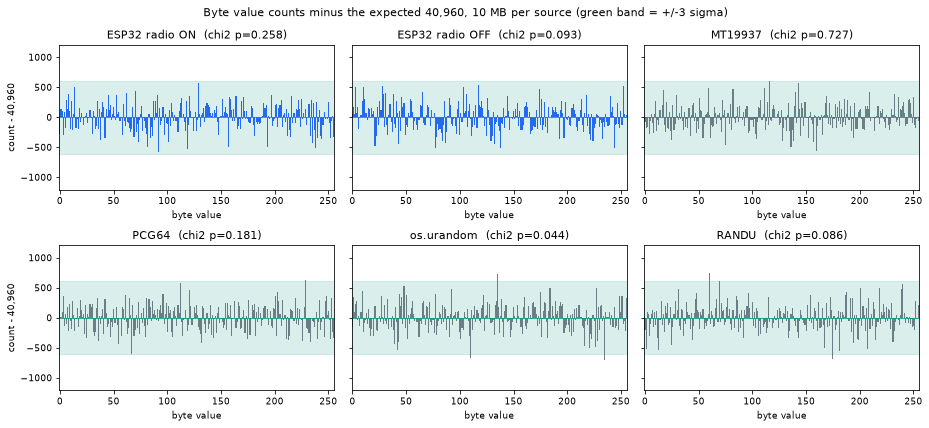

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
e = N / 256; sd = math.sqrt(e * (1 - 1 / 256))
for ax, name in zip(axes.flat, NAMES):
    c = np.bincount(SOURCES[name], minlength=256)
    ax.bar(np.arange(256), c - e, width=1.0, color='#2962ff' if 'ESP32' in name else '#787b86')
    ax.axhspan(-3 * sd, 3 * sd, color='#089981', alpha=0.15); ax.axhline(0, color='#089981', lw=0.8)
    ax.set_ylim(-6 * sd, 6 * sd); ax.set_xlim(-0.5, 255.5); ax.set_xlabel('byte value')
    if name == NAMES[0] or name == NAMES[3]: ax.set_ylabel(f'count - {e:,.0f}')
    ax.set_title(f"{name}  (chi2 p={results[name]['Byte chi-square']['p']:.3f})")
fig.suptitle(f'Byte value counts minus the expected {e:,.0f}, 10 MB per source (green band = +/-3 sigma)'); fig.tight_layout()
fig.savefig(OUT_DIR / 'byte_histograms.png', bbox_inches='tight'); plt.show()

## 5. Autocorrelation at lags 1-32

The correlation between each byte and the byte k places later. Pure noise stays inside the dashed band
(+/-2.576 / sqrt(N), the 1% line) almost everywhere.

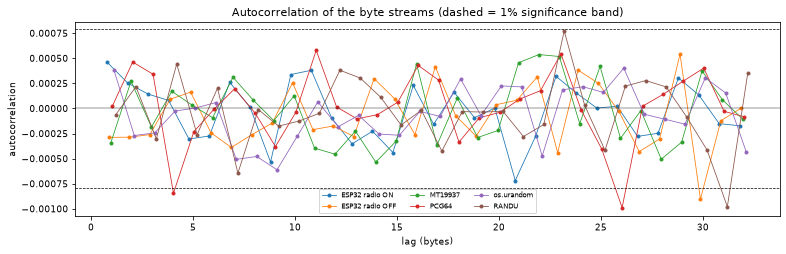

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6)); lags = np.arange(1, 33); band = 2.576 / math.sqrt(N)
for i, name in enumerate(NAMES):
    ax.plot(lags + (i - 2.5) * 0.08, acf[name], 'o-', ms=3, lw=0.8, label=name)
ax.axhline(band, ls='--', c='k', lw=0.7); ax.axhline(-band, ls='--', c='k', lw=0.7); ax.axhline(0, c='k', lw=0.4)
ax.set_xlabel('lag (bytes)'); ax.set_ylabel('autocorrelation'); ax.legend(ncol=3, fontsize=7)
ax.set_title('Autocorrelation of the byte streams (dashed = 1% significance band)')
fig.tight_layout(); fig.savefig(OUT_DIR / 'autocorrelation.png', bbox_inches='tight'); plt.show()

## 6. Bitmaps (512 x 512 bytes each)

The first 262,144 bytes of each source drawn as grey pixels. Gross failures (stuck bits, short cycles, repeats)
show up as stripes or tiles. All six look like TV static here, which is exactly why a picture is not a proof:
RANDU looks fine too. The seventh panel shows what a grossly broken stream looks like: RANDU's *lowest* byte
of each output, whose low bits repeat with very short periods.

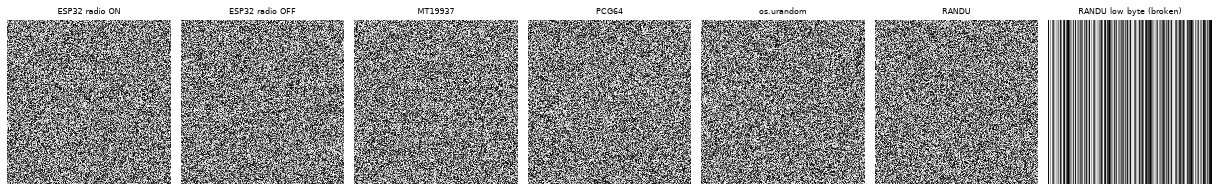

In [8]:
fig, axes = plt.subplots(1, 7, figsize=(17, 3.1))
panels = [(n, SOURCES[n]) for n in NAMES] + [('RANDU low byte (broken)', (randu & np.uint64(0xFF)).astype(np.uint8))]
for ax, (name, d) in zip(axes, panels):
    ax.imshow(d[:512 * 512].reshape(512, 512), cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(name, fontsize=8); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT_DIR / 'bitmaps.png', bbox_inches='tight'); plt.show()

## 7. RANDU's planes vs the ESP32

RANDU's multiplier 65539 = 2^16 + 3 makes every three consecutive outputs obey
x(n+2) = 6 x(n+1) - 9 x(n) (mod 2^31). So if you treat three outputs in a row as a point (u1, u2, u3) in the unit
cube, the value 9 u1 - 6 u2 + u3 is always a whole number, and all points fall on just **15 parallel planes**.
Left: the cube seen edge-on to those planes. Right: a histogram of 9 u1 - 6 u2 + u3. For RANDU it is 15 spikes;
for the ESP32 (consecutive `esp_random()` words) it is a smooth hill, because the points fill the cube.

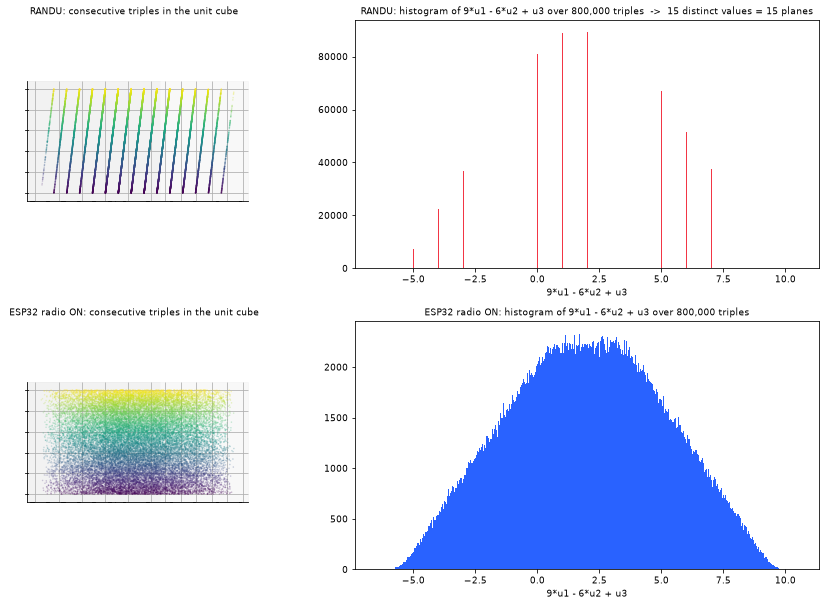

RANDU plane count: 15


In [9]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3d projection)
M3 = 30000
esp_words = np.frombuffer(SOURCES['ESP32 radio ON'].tobytes(), dtype='<u4')
trip = {'RANDU': (randu[:3 * M3].astype(np.float64) / 2 ** 31).reshape(M3, 3),
        'ESP32 radio ON': (esp_words[:3 * M3].astype(np.float64) / 2 ** 32).reshape(M3, 3)}
fig = plt.figure(figsize=(13, 8.5))
for row, (name, P) in enumerate(trip.items()):
    ax = fig.add_subplot(2, 2, 2 * row + 1, projection='3d')
    ax.scatter(P[:, 0], P[:, 1], P[:, 2], s=0.3, c=P[:, 2], cmap='viridis', alpha=0.6, rasterized=True)
    ax.set_proj_type('ortho')
    ax.view_init(elev=0, azim=56.31)     # line of sight (2, 3, 0) lies inside the planes (normal (9, -6, 1)): edge-on
    ax.set_title(f'{name}: consecutive triples in the unit cube', fontsize=9)
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    ax2 = fig.add_subplot(2, 2, 2 * row + 2)
    W = (randu[:3 * 800_000].astype(np.float64) / 2 ** 31).reshape(-1, 3) if name == 'RANDU' else \
        (esp_words[:3 * 800_000].astype(np.float64) / 2 ** 32).reshape(-1, 3)
    s = 9 * W[:, 0] - 6 * W[:, 1] + W[:, 2]
    ax2.hist(s, bins=np.linspace(-6.5, 10.5, 681), color='#f23645' if name == 'RANDU' else '#2962ff')
    distinct = len(np.unique(np.round(s, 6))) if name == 'RANDU' else None
    ax2.set_title(f'{name}: histogram of 9*u1 - 6*u2 + u3 over 800,000 triples'
                  + (f'  ->  {distinct} distinct values = {distinct} planes' if distinct else ''), fontsize=9)
    ax2.set_xlabel('9*u1 - 6*u2 + u3')
fig.tight_layout(); fig.savefig(OUT_DIR / 'randu_planes_vs_esp32.png', bbox_inches='tight'); plt.show()
print('RANDU plane count:', len(np.unique(np.round(9 * trip['RANDU'][:, 0] - 6 * trip['RANDU'][:, 1] + trip['RANDU'][:, 2], 6))))

## 8. Same seed replays exactly; two ESP32 captures share nothing

A software generator is a formula: give it the same seed and it prints the same numbers forever. The ESP32 has no
seed to share: two captures taken minutes apart (separate boots) agree on a byte only as often as chance predicts
(1 in 256), and no 16-byte chunk of one appears anywhere in the other.

In [10]:
a = np.random.default_rng(SEED).bytes(1_000_000); b = np.random.default_rng(SEED).bytes(1_000_000)
print(f'PCG64 seed {SEED}, run 1 vs run 2: identical = {a == b}   first 16 bytes: {a[:16].hex()} | {b[:16].hex()}')
m1 = random.Random(SEED).getrandbits(64); m2 = random.Random(SEED).getrandbits(64)
print(f'MT19937 seed {SEED}, run 1 vs run 2: identical = {m1 == m2}')

second = DATA_DIR / 'esp32_radio_on_2.bin'
if second.exists():
    other_name, other = 'esp32_radio_on_2.bin (separate boot)', np.fromfile(second, np.uint8)
else:
    other_name, other = 'esp32_radio_off.bin (2nd capture not uploaded)', SOURCES['ESP32 radio OFF']
n = min(len(other), 1_000_000); x = SOURCES['ESP32 radio ON'][:n]; y = other[:n]
same = float(np.mean(x == y)); big = SOURCES['ESP32 radio ON'].tobytes()
chunks = [y[i:i + 16].tobytes() for i in range(0, 16 * 200, 16)]
found = sum(big.find(c) >= 0 for c in chunks)
print(f'ESP32 radio ON vs {other_name}:')
print(f'  bytes equal at the same position: {same * 100:.3f}%  (chance = {100 / 256:.3f}%)')
print(f'  correlation: {np.corrcoef(x.astype(float), y.astype(float))[0, 1]:+.5f}')
print(f'  16-byte chunks of capture 2 found anywhere in capture 1 (10 MB): {found} of {len(chunks)}')

PCG64 seed 20261005, run 1 vs run 2: identical = True   first 16 bytes: 2af6cf480441da56395d6628b3492767 | 2af6cf480441da56395d6628b3492767
MT19937 seed 20261005, run 1 vs run 2: identical = True


ESP32 radio ON vs esp32_radio_on_2.bin (separate boot):
  bytes equal at the same position: 0.388%  (chance = 0.391%)
  correlation: +0.00023
  16-byte chunks of capture 2 found anywhere in capture 1 (10 MB): 0 of 200


## 9. Optional: `ent` and `dieharder` (Colab only)

Colab runs Linux, so it can install the classic command-line tools in a few seconds. Locally (Windows) this cell is
skipped. Note: 10 MB is short for dieharder, which rewinds the file for many tests; treat this as a sanity check,
not a full battery (PractRand on hundreds of MB would be the next step).

In [11]:
if IN_COLAB:
    subprocess.run('apt-get -qq install -y ent dieharder > /dev/null', shell=True, check=False)
    randu_path = DATA_DIR / 'randu_top_byte.bin'; SOURCES['RANDU'].tofile(randu_path)
    for f in ['esp32_radio_on.bin', 'esp32_radio_off.bin', randu_path.name]:
        print('=' * 20, 'ent', f); print(subprocess.run(['ent', str(DATA_DIR / f)], capture_output=True, text=True).stdout)
    for d in [0, 2, 3, 15, 100, 101]:   # birthdays, rank 32x32, rank 6x8, runs, sts_monobit, sts_runs
        out = subprocess.run(['dieharder', '-g', '201', '-f', str(DATA_DIR / 'esp32_radio_on.bin'), '-d', str(d)],
                             capture_output=True, text=True).stdout
        print('\n'.join(l for l in out.splitlines() if '|' in l and not l.startswith('#')))
else:
    print('Skipped: ent/dieharder run only in Google Colab (Linux). Open this notebook in Colab to run them.')

Skipped: ent/dieharder run only in Google Colab (Linux). Open this notebook in Colab to run them.


## 10. Conclusion (honest version)

- **What the tests show:** the ESP32 radio-ON stream shows **no detectable pattern** in any test here, at the same
  level as MT19937, PCG64 and the OS CSPRNG.
- **What they cannot show:** that the ESP32 is *truly* random. MT19937 and PCG64 pass too, and they are completely
  predictable from their seed (section 8). The ESP32 with its radio **off**, which Espressif says to treat as
  pseudo-random, passes too. No statistical test can tell "true random" from "good pseudo-random".
- **The tests are sharp, though:** RANDU, a generator that was used for years and is badly broken, passes every
  one-dimensional test and fails the 3D triples test hard, because all its consecutive triples lie on 15 planes
  (section 7). So a passing score means "nothing broken that these tests can see", not "too weak to notice".
- **Where the "true random" claim comes from:** the physics plus the firmware. Espressif documents that
  `esp_random()` is a true RNG while the RF subsystem is on and awake (or `bootloader_random_enable()` is active).
  GhostTape's firmware switches Wi-Fi STA on, disables modem sleep, proves the radio works with a completed Wi-Fi
  scan, re-checks every 30 s, and sends nothing (blue LED off) when that verification fails. The live tape only ever
  receives numbers produced under that condition.